In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import os
os.environ['TF_GPU_ALLOCATOR'] = 'cuda_malloc_async'
os.environ['TF_CUDNN_USE_AUTOTUNE'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'


I0000 00:00:1790307091.380724   21699 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790307093.029322   21699 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790307145.173569   21699 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
import os
path = "/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/pork_dataset"
files = os.listdir(path)
train_path = os.path.join(path, "train set")
valid_path = os.path.join(path, "valid set")
test_path = os.path.join(path, "test set")
print("โฟลเดอร์ย่อยในพาธ:", files)

โฟลเดอร์ย่อยในพาธ: ['test set', 'train set', 'unseen data', 'valid set']


In [3]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

print("จำนวนไฟล์และคลาสใน train set : ")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)
print("\n")

print("จำนวนไฟล์และคลาสใน valid set : ")
valid_dataset = tf.keras.utils.image_dataset_from_directory(
    valid_path,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)
print("\n")

print("จำนวนไฟล์และคลาสใน test set : ")
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_path,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)

จำนวนไฟล์และคลาสใน train set : 
Found 2100 files belonging to 2 classes.


I0000 00:00:1790307196.837159   21699 gpu_process_state.cc:208] Using CUDA malloc Async allocator for GPU: 0
I0000 00:00:1790307196.838628   21699 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6




จำนวนไฟล์และคลาสใน valid set : 
Found 300 files belonging to 2 classes.


จำนวนไฟล์และคลาสใน test set : 
Found 599 files belonging to 2 classes.


คลาสทั้งหมดในชุดข้อมูล: ['safe', 'unsafe']


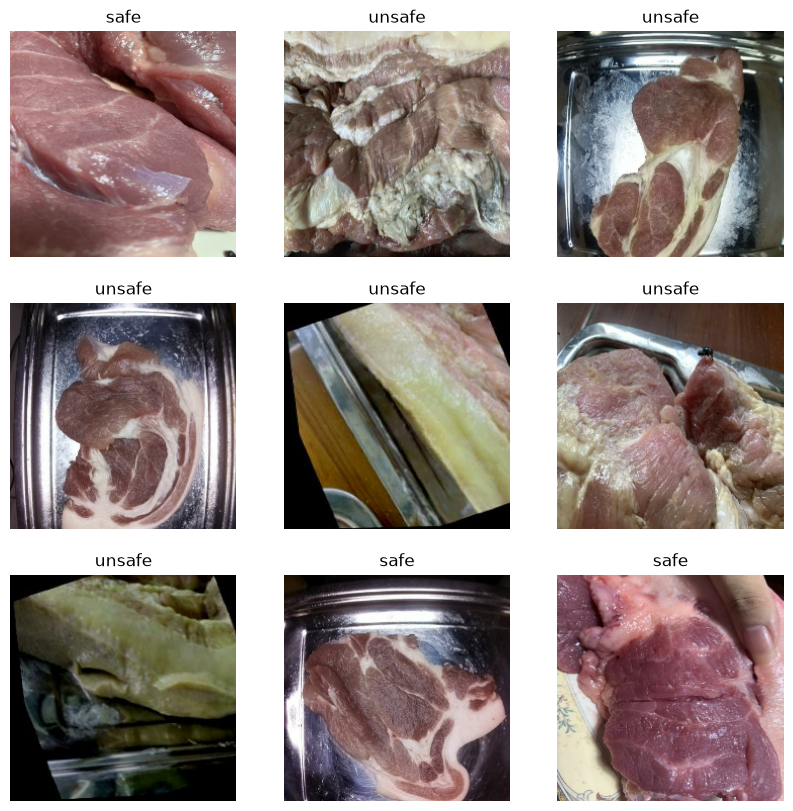

In [4]:
class_names = train_dataset.class_names
print("คลาสทั้งหมดในชุดข้อมูล:", class_names)
plt.figure(figsize=(10, 10)) 
for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

In [5]:
from tensorflow.keras.applications import MobileNetV2
base_model = MobileNetV2(input_shape=(IMAGE_SIZE[0],IMAGE_SIZE[1],3),include_top = False, weights = "imagenet")
base_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 2,223,872 (8.48 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [6]:
from tensorflow.keras.layers import Rescaling, GlobalAveragePooling2D, Dense, Input, BatchNormalization
from tensorflow.keras.models import Model

base_model.trainable = False

inputs = Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3))
custom_ann = Rescaling(1./255)(inputs)
custom_ann = base_model(custom_ann)

custom_ann = GlobalAveragePooling2D()(custom_ann)
custom_ann = tf.keras.layers.Dense(16, activation='relu', kernel_initializer='random_normal')(custom_ann)
custom_ann = BatchNormalization()(custom_ann)
custom_ann = tf.keras.layers.Dense(16, activation='relu', kernel_initializer='random_normal')(custom_ann)
custom_ann = BatchNormalization()(custom_ann)
custom_ann = tf.keras.layers.Dense(8, activation='relu', kernel_initializer='random_normal')(custom_ann)
custom_ann = tf.keras.layers.Dense(4, activation='relu', kernel_initializer='random_normal')(custom_ann)
outputs = tf.keras.layers.Dense(units=1, activation='sigmoid')(custom_ann)

model = tf.keras.models.Model(inputs=inputs, outputs=outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        20,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,279,057 (8.69 MB)

 Trainable params: 21,009 (82.07 KB)

 Non-trainable params: 2,258,048 (8.61 MB)

In [7]:
from keras.callbacks import ModelCheckpoint
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='binary_crossentropy',metrics=['accuracy'])
checkpointer = ModelCheckpoint(filepath='model.weights.best.keras',verbose=0,save_best_only=True)
history = model.fit(train_dataset, validation_data=valid_dataset, epochs=100, callbacks=[checkpointer])

Epoch 1/100


/mnt/c/Users/jiray/ml/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1790307208.204709   22122 service.cc:153] XLA service 0x7a93000692b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790307208.204740   22122 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1790307208.410120   22122 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1790307209.524351   22122 cuda_dnn.cc:461] Loaded cuDNN version 92600
I0000 00:00:1790307209.585368   22122 dot_merger.cc:481] Merging Dots in

65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.6822 - loss: 0.6345

I0000 00:00:1790307245.696999   22123 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_9937__.129


66/66 ━━━━━━━━━━━━━━━━━━━━ 92s 840ms/step - accuracy: 0.6843 - loss: 0.6332 - val_accuracy: 0.5000 - val_loss: 0.6226
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - accuracy: 0.9310 - loss: 0.4318 - val_accuracy: 0.8967 - val_loss: 0.4916
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9571 - loss: 0.3655 - val_accuracy: 0.8567 - val_loss: 0.4924
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.9657 - loss: 0.3396 - val_accuracy: 0.8900 - val_loss: 0.4376
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.9743 - loss: 0.3139 - val_accuracy: 0.9000 - val_loss: 0.3960
Epoch 6/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.9700 - loss: 0.3048 - val_accuracy: 0.9000 - val_loss: 0.4818
Epoch 7/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.9771 - loss: 0.2834 - val_accuracy: 0.8967 - val_loss: 0.5133
Epoch 8/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9795 - loss: 0.2709 - val_accuracy: 0.9033 - val

19/19 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step


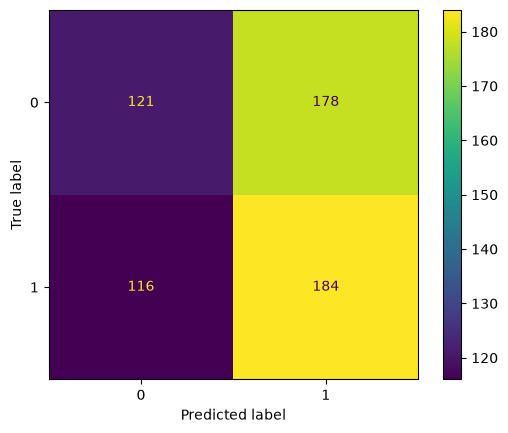

In [8]:
from sklearn.metrics import confusion_matrix, classification_report, confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = model.predict(test_dataset)
y_pred = (y_pred > 0.5).astype("int32")

y_true = []
for images, labels in test_dataset:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)

cm = ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred))

cm.plot()
plt.show()

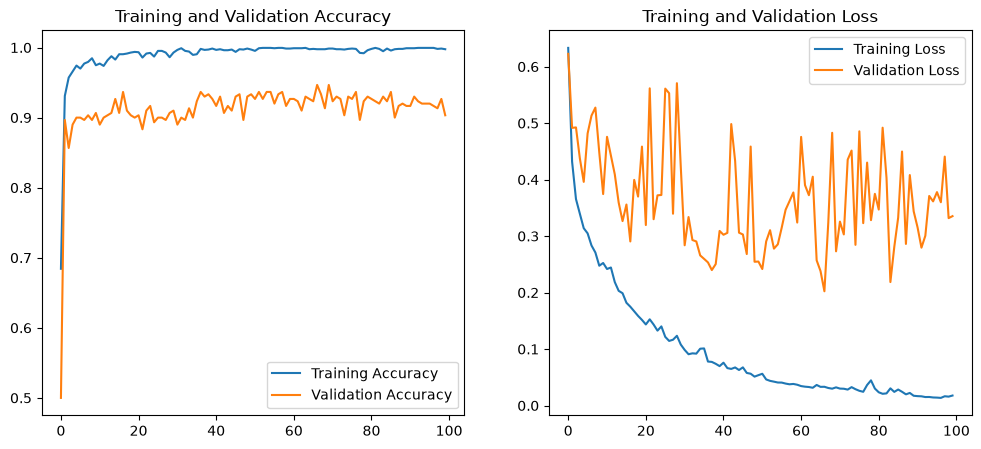

In [9]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# กราฟความแม่นยำ (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# กราฟความสูญเสีย (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [10]:
base_model.trainable = True
for layer in base_model.layers[:100]:
    layer.trainable = False
    
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='binary_crossentropy',metrics=['accuracy'])
history = model.fit(train_dataset, validation_data=valid_dataset, epochs=100, callbacks=[checkpointer])

Epoch 1/100


/mnt/c/Users/jiray/ml/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1790307676.875848   22124 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_74694__.201


65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.8716 - loss: 0.4799

I0000 00:00:1790307701.303488   22124 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_74694__.201


66/66 ━━━━━━━━━━━━━━━━━━━━ 58s 444ms/step - accuracy: 0.8714 - loss: 0.4814 - val_accuracy: 0.7833 - val_loss: 0.8877
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - accuracy: 0.9495 - loss: 0.1354 - val_accuracy: 0.8567 - val_loss: 0.5325
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.9871 - loss: 0.0541 - val_accuracy: 0.8900 - val_loss: 0.3972
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.9852 - loss: 0.0515 - val_accuracy: 0.9067 - val_loss: 0.3366
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.9848 - loss: 0.0458 - val_accuracy: 0.8633 - val_loss: 0.5111
Epoch 6/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.9867 - loss: 0.0493 - val_accuracy: 0.9000 - val_loss: 0.4768
Epoch 7/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.9929 - loss: 0.0307 - val_accuracy: 0.9400 - val_loss: 0.2095
Epoch 8/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.9976 - loss: 0.0195 - val_accuracy: 0.8733 - val

19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 192ms/step


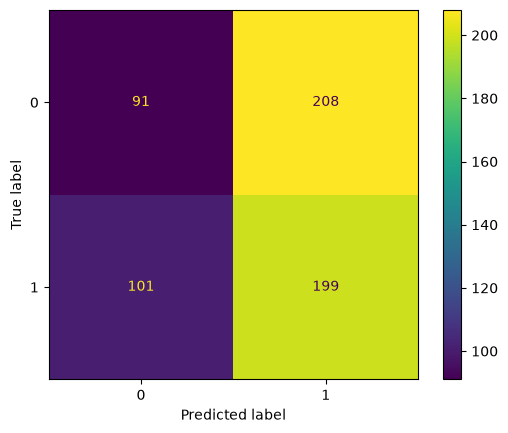

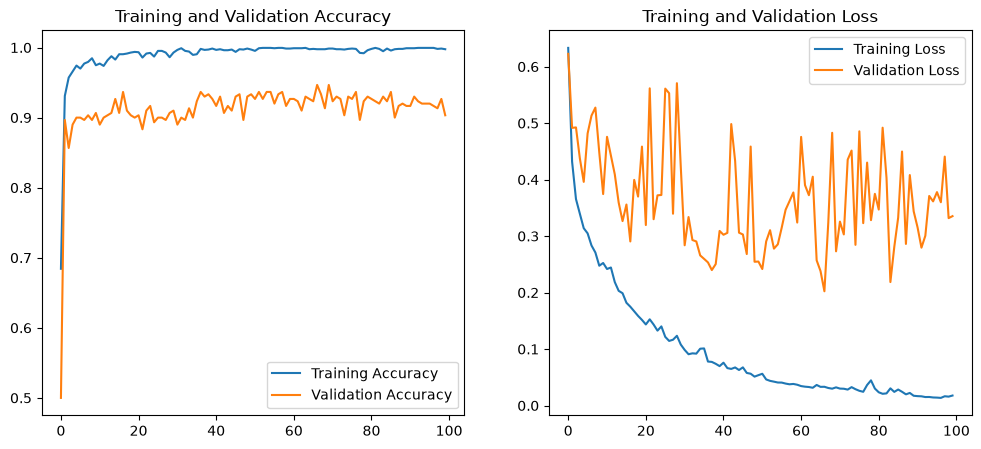

In [11]:
y_pred = model.predict(test_dataset)
y_pred = (y_pred > 0.5).astype("int32")

y_true = []
for images, labels in test_dataset:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)

cm = ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred))

cm.plot()
plt.show()
plt.figure(figsize=(12, 5))

# กราฟความแม่นยำ (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# กราฟความสูญเสีย (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [12]:
model.save('/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/model3_MobileNetV2.h5')
print('saved model to drive')

saved model to drive


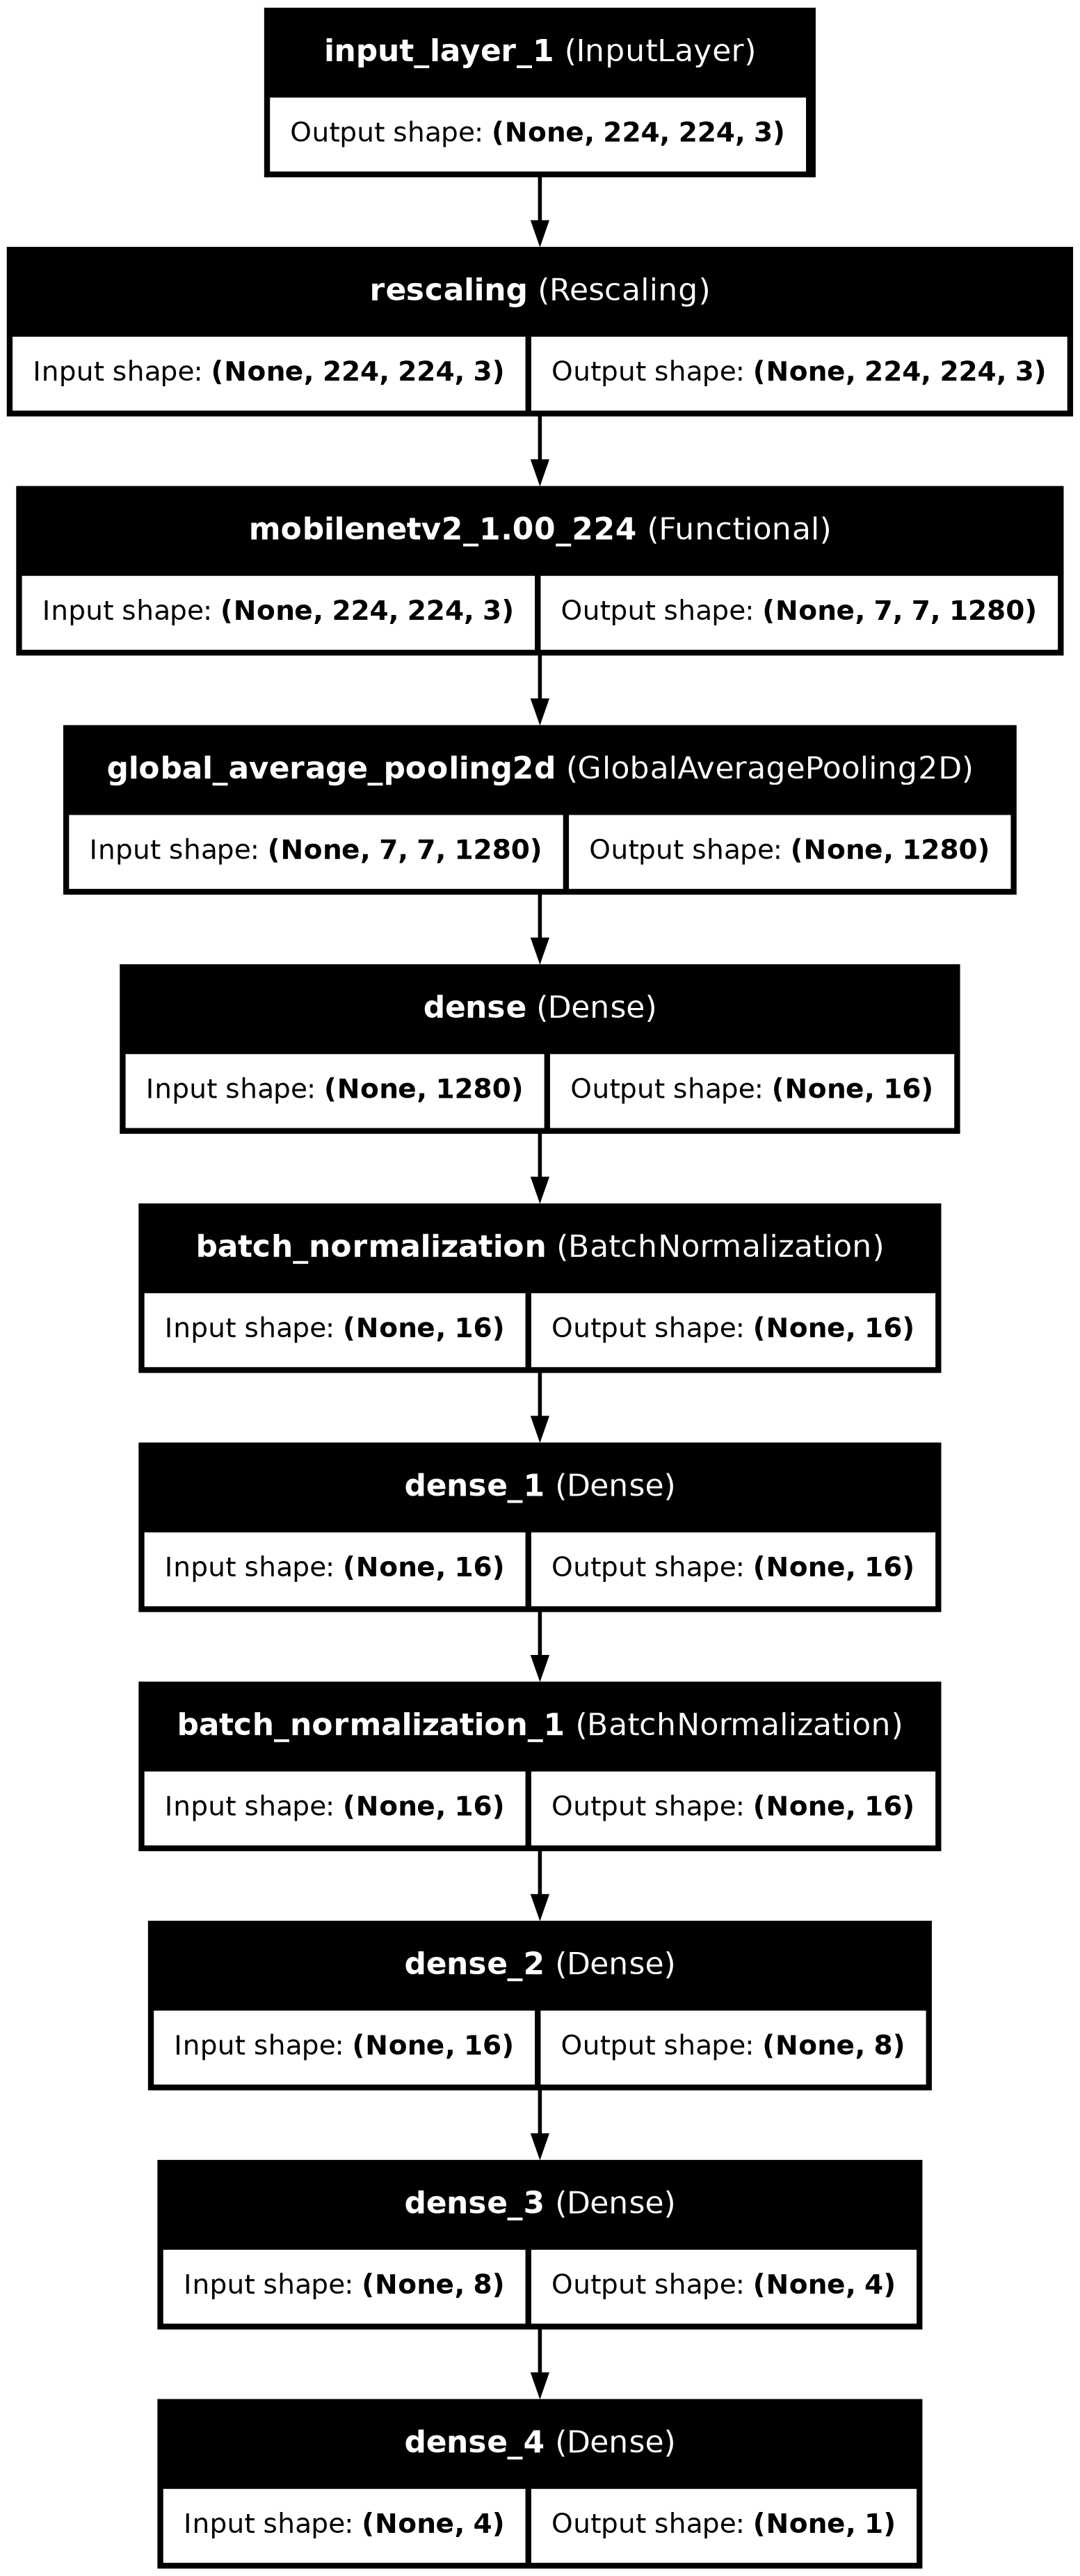

In [13]:
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    show_shapes=True,
    show_layer_names=True
)

กำลังทำนายภาพทั้งหมด 10 ภาพ...
1/1 ━━━━━━━━━━━━━━━━━━━━ 20s 20s/step


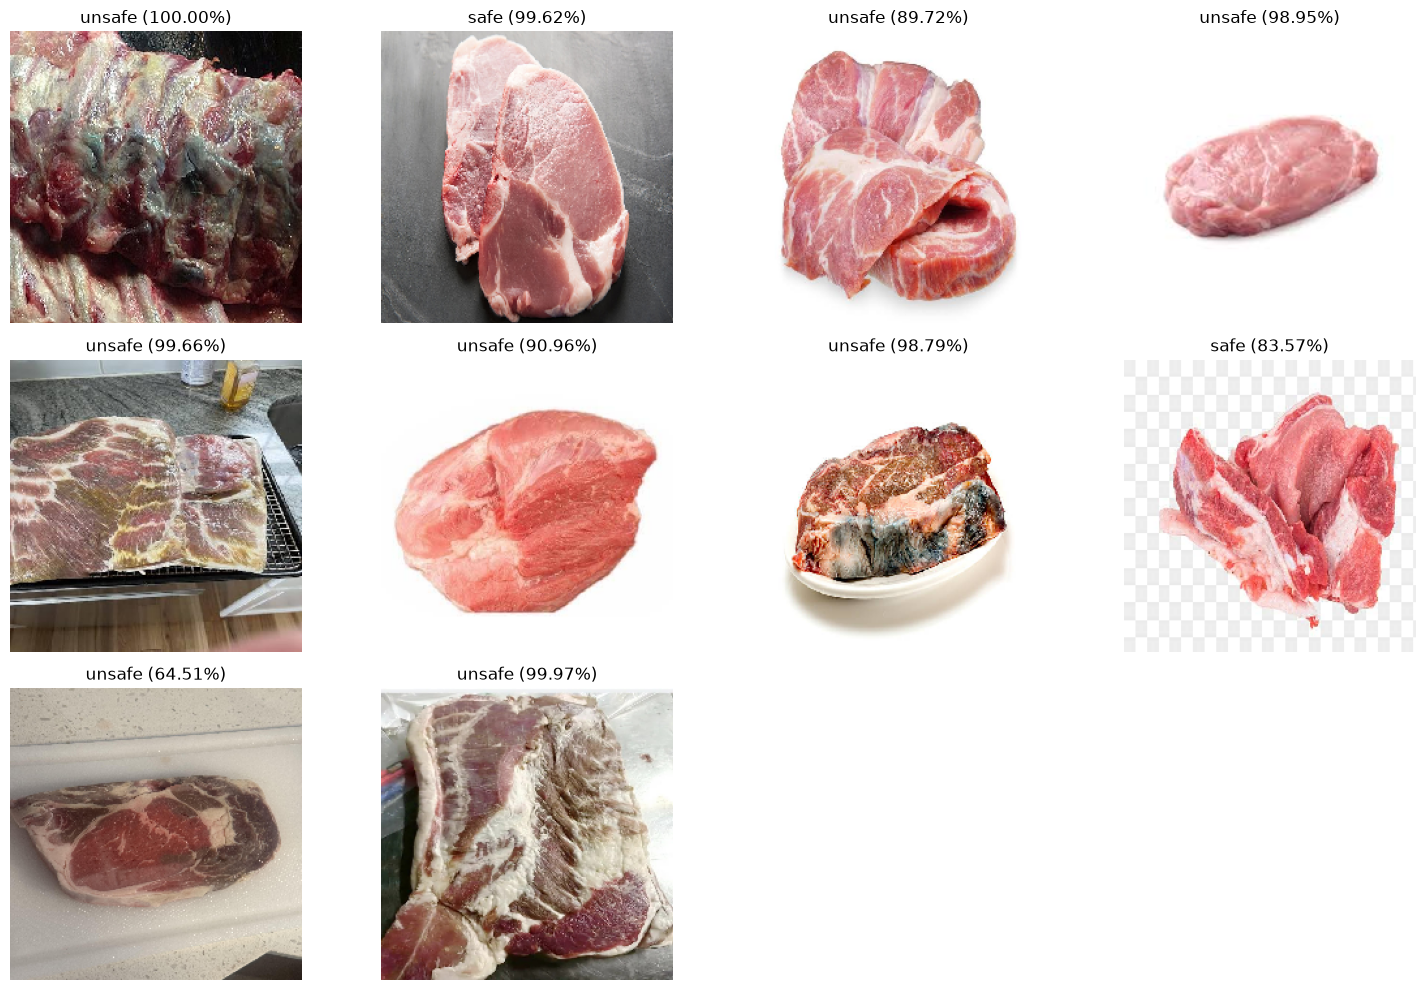

In [14]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# 1. กำหนดโฟลเดอร์ที่เก็บภาพใหม่ (เปลี่ยนชื่อโฟลเดอร์ได้ตามต้องการ)
unseen_dir = r"/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/pork_dataset/unseen data"

# ดึงเฉพาะไฟล์รูปภาพมาเก็บไว้ในลิสต์
image_filenames = [f for f in os.listdir(unseen_dir) if f.endswith(('.png', '.jpg', '.jpeg'))]

IMAGE_SIZE = (224, 224)
class_names = ['safe', 'unsafe']  # อ้างอิงลำดับตามโฟลเดอร์ Train set

# 2. เตรียมข้อมูล: โหลดภาพและแปลงเป็นอาร์เรย์ (Array)
img_arrays = []
for filename in image_filenames:
    img_path = os.path.join(unseen_dir, filename)
    img = load_img(img_path, target_size=IMAGE_SIZE)
    img_array = img_to_array(img)
    img_arrays.append(img_array)

# นำภาพทั้งหมดมาต่อกันเป็น Batch รูปร่างจะเป็น (จำนวนภาพ, 256, 256, 3)
img_batch = np.array(img_arrays)

# 3. สั่งให้โมเดลทำนายผลรวดเดียวทุกภาพ
print(f"กำลังทำนายภาพทั้งหมด {len(image_filenames)} ภาพ...")
predictions = model.predict(img_batch)

# 4. พล็อตกราฟแสดงรูปภาพ คลาสที่ทำนายได้ และเปอร์เซ็นต์ความมั่นใจ
plt.figure(figsize=(15, 10))
for i in range(len(image_filenames)):
    # กำหนดให้แสดงผลแถวละ 4 ภาพ
    plt.subplot((len(image_filenames) // 4) + 1, 4, i + 1)
    
    # แสดงรูปภาพ (ต้องแปลงกลับเป็น uint8 เพื่อให้ภาพแสดงสีถูกต้อง)
    plt.imshow(img_arrays[i].astype("uint8"))
    
    # ดึงคะแนน (Score) จาก Sigmoid (0 ถึง 1)
    # ถ้าเกิน 0.5 แปลว่าโมเดลเอนเอียงไปทางคลาส 1 ('unsafe')
    score = predictions[i][0]
    if score > 0.5:
        predicted_class = class_names[1]
        confidence = score * 100
    else:
        predicted_class = class_names[0]
        confidence = (1 - score) * 100
        
    plt.title(f"{predicted_class} ({confidence:.2f}%)")
    plt.axis("off")

plt.tight_layout()
plt.show()